In [ ]:
import sys
import os

from script.ECMpy_function import get_enzyme_constraint_model_with_reaction_set_exclusion

sys.path.append(r'./script/')
from ECMpy_function import *
import cobra
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 重置并设置matplotlib全局参数
plt.rcdefaults()
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.edgecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.0
plt.rcParams['ytick.minor.width'] = 1.0
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'

# Model file paths
model_files = [
    './model_Calibration/catpred_Calibration/ecCZ870_catpred_Calibration.json',
    './model_Calibration/catapro_Calibration/ecCZ870_catapro_Calibration.json',
    './model_Calibration/DLKcat_Calibration/ecCZ870_DLKcat_Calibration.json',
    './model_Calibration/UniKP_Calibration/ecCZ870_UniKP_Calibration.json',
    './model_Calibration/AutoPACMEN_mean_Calibration/ecCZ870_AutoPACMEN_mean_Calibration.json',
    './model_Calibration/AutoPACMEN_median_Calibration/ecCZ870_AutoPACMEN_median_Calibration.json',
]

# Model names
model_names = [
    'ecCZ870_catpred',
    'ecCZ870_catapro',
    'ecCZ870_DLKcat',
    'ecCZ870_UniKP',
    'ecCZ870_AutoPACMEN_mean',
    'ecCZ870_AutoPACMEN_median',
]

# Color palette
colors = [
    '#91CCC0',
    '#8B5BCC',
    '#7FABD1',
    '#F7AC53',
    '#EC6E66',
    '#B5CE4E',
]

# Line styles and markers
line_styles = ['-'] * 6
markers = ['o', 's', '^', 'v', 'D', 'X']

# Biomass reaction IDs
biomass_ids = ['Bio_cgATCC14067_c'] * 6

# Target reaction
target_reaction = 'EX_cpd00027_e_reverse'

# Flux range
num_points = 50
flux_range = np.linspace(0, 40, num_points)

# Experimental data
gur_values = [2.33, 3.44, 4.27, 4.086, 4.8, 5.1]
exp_values = [0.2, 0.3, 0.4, 0.41, 0.42, 0.46]

# Analyze single model
def analyze_model(model_file, model_name, biomass_id, target_reaction_id, flux_range):
    try:
        print(f"Loading model: {model_name}...")
        enz_model = get_enzyme_constraint_model(model_file)
        enz_model.objective = enz_model.reactions.get_by_id(biomass_id)

        if target_reaction_id not in [r.id for r in enz_model.reactions]:
            print(f"Warning: Target reaction {target_reaction_id} not found in model {model_name}")
            return np.zeros(len(flux_range))

        target_reaction_obj = enz_model.reactions.get_by_id(target_reaction_id)
        growth_rates = np.zeros(len(flux_range))

        print(f"Analyzing model: {model_name}...")

        for j, flux in enumerate(flux_range):
            target_reaction_obj.bounds = (flux, flux)
            try:
                solution = enz_model.optimize()
                if solution.status == 'optimal':
                    growth_rates[j] = solution.objective_value
            except Exception as e:
                print(f"  Optimization error at flux {flux}: {str(e)[:100]}...")

        max_growth = np.max(growth_rates)
        max_index = np.argmax(growth_rates)
        print(f"Analysis complete: {model_name}")
        print(f"  Maximum growth rate: {max_growth:.4f} at flux {flux_range[max_index]:.2f}")

        return growth_rates

    except Exception as e:
        print(f"Error processing model {model_name}: {str(e)}")
        return np.zeros(len(flux_range))

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

print("Starting model analysis...")

# Store results
all_growth_rates = []
results_df = pd.DataFrame(index=flux_range)

# Analyze each model
for i, (model_file, model_name, biomass_id) in enumerate(zip(model_files, model_names, biomass_ids)):
    growth_rates = analyze_model(model_file, model_name, biomass_id, target_reaction, flux_range)
    all_growth_rates.append(growth_rates)
    results_df[model_name] = growth_rates

    ax.plot(flux_range, growth_rates, color=colors[i], linestyle=line_styles[i],
            marker=markers[i], markevery=3, markersize=7, linewidth=2.5,
            label=model_name, markeredgewidth=1.2, markeredgecolor=colors[i])

# Add experimental data
ax.scatter(gur_values, exp_values, marker='o', color='black', s=100,
           label='Experimental Data', edgecolor='black', linewidth=2, zorder=10)

# Set limits
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.7)

# Labels and title
ax.set_xlabel('Glucose Uptake Rate (mmol/gDW/h)', fontsize=13, fontweight='bold')
ax.set_ylabel('Growth Rate (/h)', fontsize=13, fontweight='bold')
ax.set_title('Relationship Between Substrate Uptake Rate and Growth Rate\nComparison of Six Models',
             fontsize=14, fontweight='bold', pad=15)

# Tick parameters - only bottom and left
ax.tick_params(axis='x', which='major', labelsize=11, bottom=True, top=False,
               labelbottom=True, labeltop=False)
ax.tick_params(axis='y', which='major', labelsize=11, left=True, right=False,
               labelleft=True, labelright=False)
ax.tick_params(axis='both', which='minor', bottom=True, top=False, left=True, right=False)

# Grid
ax.grid(True, which='major', linestyle='-', alpha=0.3, linewidth=1.0, color='gray')
ax.grid(True, which='minor', linestyle=':', alpha=0.2, linewidth=0.5, color='gray')
ax.minorticks_on()

# Spines
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')

# Legend
legend = ax.legend(loc='upper left', fontsize=10, framealpha=1.0,
                   edgecolor='black', fancybox=False, facecolor='white',
                   frameon=True, shadow=False, borderpad=0.7,
                   labelspacing=0.5, handlelength=2.0)
legend.get_frame().set_linewidth(1.5)

plt.tight_layout()

# Save figures
plt.savefig('comparison6model_Calibration.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none', transparent=False)

# Save data
results_df.to_csv('comparison6model_results_Calibration.csv')

print("Analysis complete. Figure saved as 'comparison_single_view.png'")
print("Numerical results saved as 'model_comparison_results.csv'")

In [ ]:
import sys
import os

from script.ECMpy_function import get_enzyme_constraint_model_with_reaction_set_exclusion

sys.path.append(r'./script/')
from ECMpy_function import *
import cobra
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 重置并设置matplotlib全局参数
plt.rcdefaults()
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.edgecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.0
plt.rcParams['ytick.minor.width'] = 1.0
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'

# Model file paths
model_files = [
    './model_Calibration/catpred_Calibration/ecCZ870_catpred_Calibration.json',
    './model_Calibration/catapro_Calibration/ecCZ870_catapro_Calibration.json',
    './model_Calibration/DLKcat_Calibration/ecCZ870_DLKcat_Calibration_modify.json',
    './model_Calibration/UniKP_Calibration/ecCZ870_UniKP_Calibration.json',
    './model_Calibration/AutoPACMEN_mean_Calibration/ecCZ870_AutoPACMEN_mean_Calibration.json',
    './model_Calibration/AutoPACMEN_median_Calibration/ecCZ870_AutoPACMEN_median_Calibration.json',
]

# Model names
model_names = [
    'ecCZ870_catpred',
    'ecCZ870_catapro',
    'ecCZ870_DLKcat',
    'ecCZ870_UniKP',
    'ecCZ870_AutoPACMEN_mean',
    'ecCZ870_AutoPACMEN_median',
]

# Color palette
colors = [
    '#91CCC0',
    '#8B5BCC',
    '#7FABD1',
    '#F7AC53',
    '#EC6E66',
    '#B5CE4E',
]

# Line styles and markers
line_styles = ['-'] * 6
markers = ['o', 's', '^', 'v', 'D', 'X']

# Biomass reaction IDs
biomass_ids = ['Bio_cgATCC14067_c'] * 6

# Target reaction
target_reaction = 'EX_cpd00027_e_reverse'

# Flux range
num_points = 50
flux_range = np.linspace(0, 40, num_points)

# Experimental data
gur_values = [2.33, 3.44, 4.27, 4.086, 4.8, 5.1]
exp_values = [0.2, 0.3, 0.4, 0.41, 0.42, 0.46]

# Analyze single model
def analyze_model(model_file, model_name, biomass_id, target_reaction_id, flux_range):
    try:
        print(f"Loading model: {model_name}...")
        enz_model = get_enzyme_constraint_model(model_file)
        enz_model.objective = enz_model.reactions.get_by_id(biomass_id)

        if target_reaction_id not in [r.id for r in enz_model.reactions]:
            print(f"Warning: Target reaction {target_reaction_id} not found in model {model_name}")
            return np.zeros(len(flux_range))

        target_reaction_obj = enz_model.reactions.get_by_id(target_reaction_id)
        growth_rates = np.zeros(len(flux_range))

        print(f"Analyzing model: {model_name}...")

        for j, flux in enumerate(flux_range):
            target_reaction_obj.bounds = (flux, flux)
            try:
                solution = enz_model.optimize()
                if solution.status == 'optimal':
                    growth_rates[j] = solution.objective_value
            except Exception as e:
                print(f"  Optimization error at flux {flux}: {str(e)[:100]}...")

        max_growth = np.max(growth_rates)
        max_index = np.argmax(growth_rates)
        print(f"Analysis complete: {model_name}")
        print(f"  Maximum growth rate: {max_growth:.4f} at flux {flux_range[max_index]:.2f}")

        return growth_rates

    except Exception as e:
        print(f"Error processing model {model_name}: {str(e)}")
        return np.zeros(len(flux_range))

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

print("Starting model analysis...")

# Store results
all_growth_rates = []
results_df = pd.DataFrame(index=flux_range)

# Analyze each model
for i, (model_file, model_name, biomass_id) in enumerate(zip(model_files, model_names, biomass_ids)):
    growth_rates = analyze_model(model_file, model_name, biomass_id, target_reaction, flux_range)
    all_growth_rates.append(growth_rates)
    results_df[model_name] = growth_rates

    ax.plot(flux_range, growth_rates, color=colors[i], linestyle=line_styles[i],
            marker=markers[i], markevery=3, markersize=7, linewidth=2.5,
            label=model_name, markeredgewidth=1.2, markeredgecolor=colors[i])

# Add experimental data
ax.scatter(gur_values, exp_values, marker='o', color='black', s=100,
           label='Experimental Data', edgecolor='black', linewidth=2, zorder=10)

# Set limits
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.7)

# Labels and title
ax.set_xlabel('Glucose Uptake Rate (mmol/gDW/h)', fontsize=13, fontweight='bold')
ax.set_ylabel('Growth Rate (/h)', fontsize=13, fontweight='bold')
ax.set_title('Relationship Between Substrate Uptake Rate and Growth Rate\nComparison of Six Models',
             fontsize=14, fontweight='bold', pad=15)

# Tick parameters - only bottom and left
ax.tick_params(axis='x', which='major', labelsize=11, bottom=True, top=False,
               labelbottom=True, labeltop=False)
ax.tick_params(axis='y', which='major', labelsize=11, left=True, right=False,
               labelleft=True, labelright=False)
ax.tick_params(axis='both', which='minor', bottom=True, top=False, left=True, right=False)

# Grid
ax.grid(True, which='major', linestyle='-', alpha=0.3, linewidth=1.0, color='gray')
ax.grid(True, which='minor', linestyle=':', alpha=0.2, linewidth=0.5, color='gray')
ax.minorticks_on()

# Spines
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')

# Legend
legend = ax.legend(loc='upper left', fontsize=10, framealpha=1.0,
                   edgecolor='black', fancybox=False, facecolor='white',
                   frameon=True, shadow=False, borderpad=0.7,
                   labelspacing=0.5, handlelength=2.0)
legend.get_frame().set_linewidth(1.5)

plt.tight_layout()

# Save figures
plt.savefig('comparison6model_modify.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none', transparent=False)

# Save data
results_df.to_csv('comparison6model_results_modify.csv')

print("Analysis complete. Figure saved as 'comparison_single_view.png'")
print("Numerical results saved as 'model_comparison_results.csv'")

No objective coefficients in model. Unclear what should be optimized



Loading & analyzing: iCZ870 (original)
Done: iCZ870 (original) | optimal points = 50/50

Loading & analyzing: ecCZ870 (DLKcat)
Done: ecCZ870 (DLKcat) | optimal points = 50/50

All done.
Figure saved: overflow_iCZ870_vs_ecCZ870_combined.png
Table  saved: overflow_iCZ870_vs_ecCZ870.csv
Note: glucose rxn used is recorded in each df as 'glc_rxn_used' for debugging.


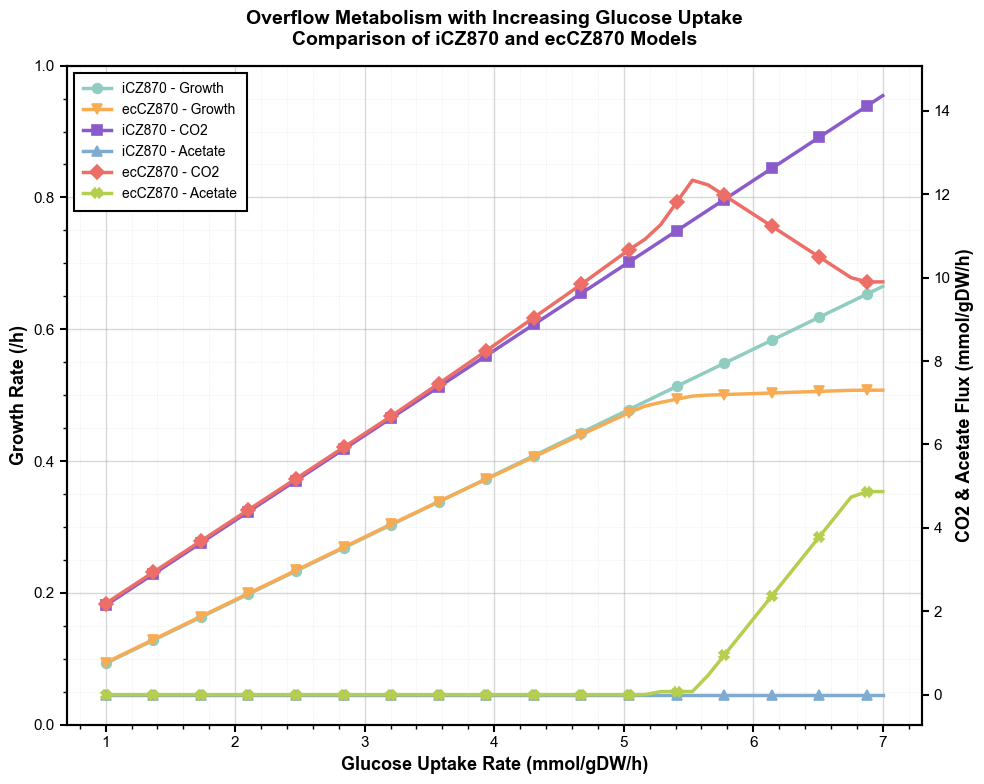

In [9]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ========== 你的 ECMpy 函数 ==========
sys.path.append(r'./script/')
from ECMpy_function import get_enzyme_constraint_model

# ========== 画图风格（沿用代码2的风格） ==========
plt.rcdefaults()
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.edgecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.0
plt.rcParams['ytick.minor.width'] = 1.0
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'

# ========== 输入模型路径（按你要求） ==========
MODEL_ICZ870 = 'iCZ870_MM.xml'
MODEL_ECCZ870 = 'model_Calibration/DLKcat_Calibration/ecCZ870_DLKcat_Calibration_modify.json'

# ========== 反应ID（按你要求） ==========
RXN_GLC_REV = 'EX_cpd00027_e_reverse'  # 你之前脚本中用的"反向反应"，正值代表摄入
RXN_GLC_STD = 'EX_cpd00027_e'          # 常规交换反应，通常负值代表摄入

RXN_BIOMASS = 'EX_biomass_c'
RXN_CO2 = 'EX_cpd00011_e'
RXN_AC = 'EX_cpd00029_e'

# ========== 葡萄糖摄入扫描范围 ==========
num_points = 50
glc_uptake_range = np.linspace(1, 7, num_points)  # mmol/gDW/h

# ========== 小工具函数 ==========
def _rxn_exists(model, rxn_id: str) -> bool:
    return rxn_id in [r.id for r in model.reactions]

def set_glucose_uptake(model, uptake_value):
    """
    兼容两种形式：
    1) EX_cpd00027_e_reverse 存在：固定该反应通量 = uptake_value (>=0)
    2) 否则使用 EX_cpd00027_e：固定交换下界 = -uptake_value，上界=0 （摄入为负）
    """
    if _rxn_exists(model, RXN_GLC_REV):
        r = model.reactions.get_by_id(RXN_GLC_REV)
        r.bounds = (uptake_value, uptake_value)
        return RXN_GLC_REV
    elif _rxn_exists(model, RXN_GLC_STD):
        r = model.reactions.get_by_id(RXN_GLC_STD)
        r.bounds = (-uptake_value, 0.0)
        return RXN_GLC_STD
    else:
        raise KeyError(f'Glucose exchange reaction not found: neither {RXN_GLC_REV} nor {RXN_GLC_STD} exists.')

def safe_get_flux(solution, model, rxn_id):
    if rxn_id not in [r.id for r in model.reactions]:
        return np.nan
    try:
        return float(solution.fluxes[rxn_id])
    except Exception:
        # 有些求解器/版本下 fluxes 取值方式不同，这里兜底
        return float(solution.fluxes.get(rxn_id, np.nan))

def set_objective_to_biomass(model):
    if _rxn_exists(model, RXN_BIOMASS):
        model.objective = model.reactions.get_by_id(RXN_BIOMASS)
        return RXN_BIOMASS
    else:
        # 如果确实不存在，就给出更明确的报错，避免默默用错目标
        raise KeyError(f'Biomass reaction {RXN_BIOMASS} not found in model. Please confirm biomass rxn id.')

def analyze_overflow(model, model_label, uptake_range):
    """
    返回 DataFrame：index=uptake，列包含 growth/CO2/acetate 及状态
    """
    print(f'\nLoading & analyzing: {model_label}')
    set_objective_to_biomass(model)

    records = []
    for v in uptake_range:
        with model:
            # 固定葡萄糖摄入
            glc_rid = set_glucose_uptake(model, v)

            # 求解
            try:
                sol = model.optimize()
            except Exception as e:
                records.append({
                    'glc_uptake': v,
                    'status': f'error:{str(e)[:80]}',
                    'growth(EX_biomass_c)': np.nan,
                    'CO2(EX_cpd00011_e)': np.nan,
                    'Acetate(EX_cpd00029_e)': np.nan,
                    'glc_rxn_used': glc_rid
                })
                continue

            if sol.status != 'optimal':
                records.append({
                    'glc_uptake': v,
                    'status': sol.status,
                    'growth(EX_biomass_c)': np.nan,
                    'CO2(EX_cpd00011_e)': np.nan,
                    'Acetate(EX_cpd00029_e)': np.nan,
                    'glc_rxn_used': glc_rid
                })
                continue

            records.append({
                'glc_uptake': v,
                'status': sol.status,
                'growth(EX_biomass_c)': safe_get_flux(sol, model, RXN_BIOMASS),
                'CO2(EX_cpd00011_e)': safe_get_flux(sol, model, RXN_CO2),
                'Acetate(EX_cpd00029_e)': safe_get_flux(sol, model, RXN_AC),
                'glc_rxn_used': glc_rid
            })

    df = pd.DataFrame.from_records(records).set_index('glc_uptake')
    print(f'Done: {model_label} | optimal points = {(df["status"]=="optimal").sum()}/{len(df)}')
    return df

# ========== 读取模型 ==========
# 原始模型（SBML）
model_ic = cobra.io.read_sbml_model(MODEL_ICZ870)

# 酶约束模型（JSON，经 ECMpy 处理）
model_ec = get_enzyme_constraint_model(MODEL_ECCZ870)

# ========== 计算 ==========
df_ic = analyze_overflow(model_ic, 'iCZ870 (original)', glc_uptake_range)
df_ec = analyze_overflow(model_ec, 'ecCZ870 (DLKcat)', glc_uptake_range)

# 合并保存
out = pd.concat(
    [df_ic.add_prefix('iCZ870_'), df_ec.add_prefix('ecCZ870_')],
    axis=1
)
out.to_csv('overflow_iCZ870_vs_ecCZ870.csv')

# ========== 作图：一张图显示三个指标（双y轴） ==========
fig, ax1 = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('white')
ax1.set_facecolor('white')

# 创建第二个y轴
ax2 = ax1.twinx()

# 使用代码2的配色方案
# iCZ870 使用前三种颜色，ecCZ870 使用后三种颜色
colors_ic = ['#91CCC0', '#8B5BCC', '#7FABD1']  # Growth, CO2, Acetate for iCZ870
colors_ec = ['#F7AC53', '#EC6E66', '#B5CE4E']  # Growth, CO2, Acetate for ecCZ870

# 线型和标记
markers_ic = ['o', 's', '^']
markers_ec = ['v', 'D', 'X']
lw = 2.5

# 左轴（ax1）：绘制 Growth（数值较小）
line1 = ax1.plot(df_ic.index, df_ic['growth(EX_biomass_c)'],
                 color=colors_ic[0], lw=lw, marker=markers_ic[0], markevery=3,
                 markersize=7, label='iCZ870 - Growth', markeredgewidth=1.2,
                 markeredgecolor=colors_ic[0])

line2 = ax1.plot(df_ec.index, df_ec['growth(EX_biomass_c)'],
                 color=colors_ec[0], lw=lw, marker=markers_ec[0], markevery=3,
                 markersize=7, label='ecCZ870 - Growth', markeredgewidth=1.2,
                 markeredgecolor=colors_ec[0])

# 右轴（ax2）：绘制 CO2 和 Acetate（数值较大）
line3 = ax2.plot(df_ic.index, df_ic['CO2(EX_cpd00011_e)'],
                 color=colors_ic[1], lw=lw, marker=markers_ic[1], markevery=3,
                 markersize=7, label='iCZ870 - CO2', markeredgewidth=1.2,
                 markeredgecolor=colors_ic[1])

line4 = ax2.plot(df_ic.index, df_ic['Acetate(EX_cpd00029_e)'],
                 color=colors_ic[2], lw=lw, marker=markers_ic[2], markevery=3,
                 markersize=7, label='iCZ870 - Acetate', markeredgewidth=1.2,
                 markeredgecolor=colors_ic[2])

line5 = ax2.plot(df_ec.index, df_ec['CO2(EX_cpd00011_e)'],
                 color=colors_ec[1], lw=lw, marker=markers_ec[1], markevery=3,
                 markersize=7, label='ecCZ870 - CO2', markeredgewidth=1.2,
                 markeredgecolor=colors_ec[1])

line6 = ax2.plot(df_ec.index, df_ec['Acetate(EX_cpd00029_e)'],
                 color=colors_ec[2], lw=lw, marker=markers_ec[2], markevery=3,
                 markersize=7, label='ecCZ870 - Acetate', markeredgewidth=1.2,
                 markeredgecolor=colors_ec[2])

# 设置标签和标题
ax1.set_xlabel('Glucose Uptake Rate (mmol/gDW/h)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Growth Rate (/h)', fontsize=13, fontweight='bold', color='black')
ax2.set_ylabel('CO2 & Acetate Flux (mmol/gDW/h)', fontsize=13, fontweight='bold', color='black')
ax1.set_title('Overflow Metabolism with Increasing Glucose Uptake\nComparison of iCZ870 and ecCZ870 Models',
              fontsize=14, fontweight='bold', pad=15)

# 设置左轴y轴范围
ax1.set_ylim(0, 1)

# Tick 参数 - ax1 (左轴)
ax1.tick_params(axis='x', which='major', labelsize=11, bottom=True, top=False,
                labelbottom=True, labeltop=False, width=1.5)
ax1.tick_params(axis='y', which='major', labelsize=11, left=True, right=False,
                labelleft=True, labelright=False, width=1.5, labelcolor='black')
ax1.tick_params(axis='both', which='minor', bottom=True, top=False, left=True, right=False, width=1.0)

# Tick 参数 - ax2 (右轴)
ax2.tick_params(axis='y', which='major', labelsize=11, left=False, right=True,
                labelleft=False, labelright=True, width=1.5, labelcolor='black')
ax2.tick_params(axis='y', which='minor', left=False, right=True, width=1.0)

# 网格 (只在ax1上设置，避免重复)
ax1.grid(True, which='major', linestyle='-', alpha=0.3, linewidth=1.0, color='gray')
ax1.grid(True, which='minor', linestyle=':', alpha=0.2, linewidth=0.5, color='gray')
ax1.minorticks_on()

# 边框
for spine in ax1.spines.values():
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')
for spine in ax2.spines.values():
    spine.set_linewidth(1.5)
    spine.set_edgecolor('black')

# 合并图例 - 按顺序一列显示
lines = line1 + line2 + line3 + line4 + line5 + line6
labels = [l.get_label() for l in lines]
legend = ax1.legend(lines, labels, loc='upper left', fontsize=10, framealpha=1.0,
                    edgecolor='black', fancybox=False, facecolor='white',
                    frameon=True, shadow=False, borderpad=0.7,
                    labelspacing=0.5, handlelength=2.0, ncol=1)
legend.get_frame().set_linewidth(1.5)

plt.tight_layout()
plt.savefig('overflow_iCZ870_vs_ecCZ870_combined.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none', transparent=False)

print("\nAll done.")
print("Figure saved: overflow_iCZ870_vs_ecCZ870_combined.png")
print("Table  saved: overflow_iCZ870_vs_ecCZ870.csv")
print("Note: glucose rxn used is recorded in each df as 'glc_rxn_used' for debugging.")